=== File: 1500.csv ===
Autocorrelation FWHM (mm): 0.12972 mm
Pulse Duration (tau_p): 0.612 ps


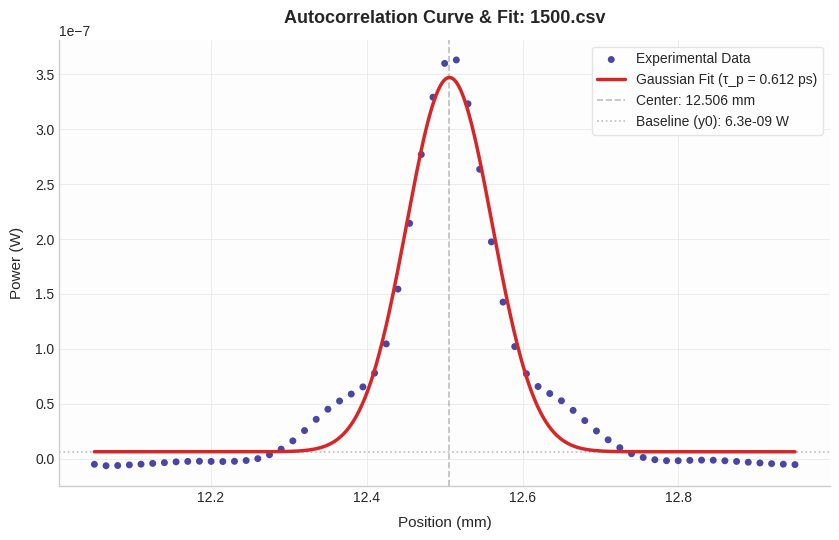

--------------------------------------------------

=== File: 1800.csv ===
Autocorrelation FWHM (mm): 0.13111 mm
Pulse Duration (tau_p): 0.619 ps


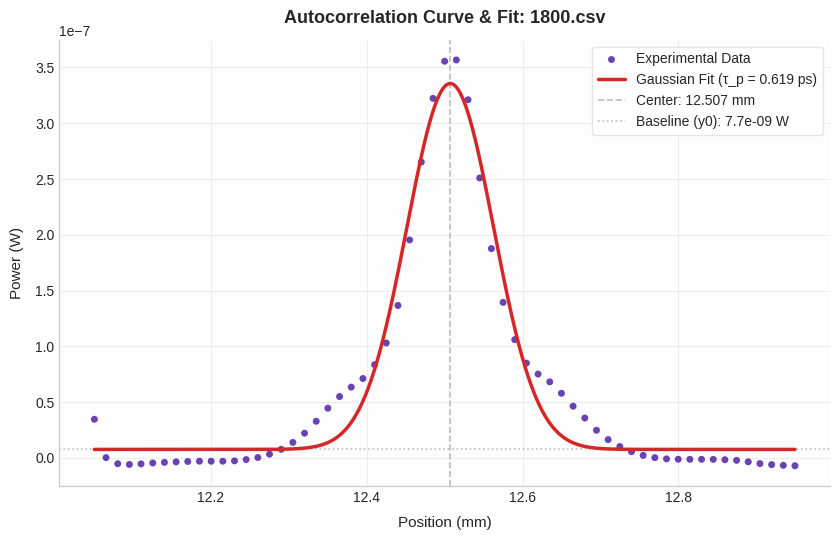

--------------------------------------------------

=== File: 2100.csv ===
Autocorrelation FWHM (mm): 0.14775 mm
Pulse Duration (tau_p): 0.697 ps


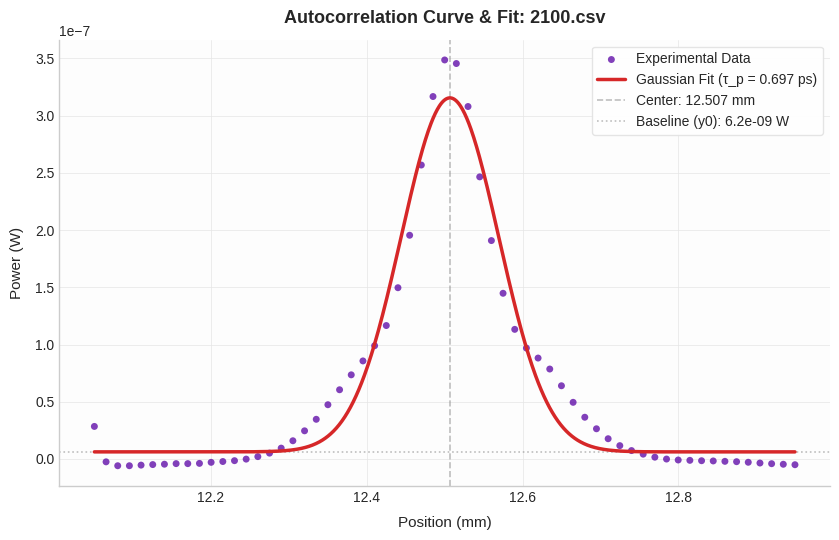

--------------------------------------------------

=== File: 2200.csv ===
Autocorrelation FWHM (mm): 0.14932 mm
Pulse Duration (tau_p): 0.704 ps


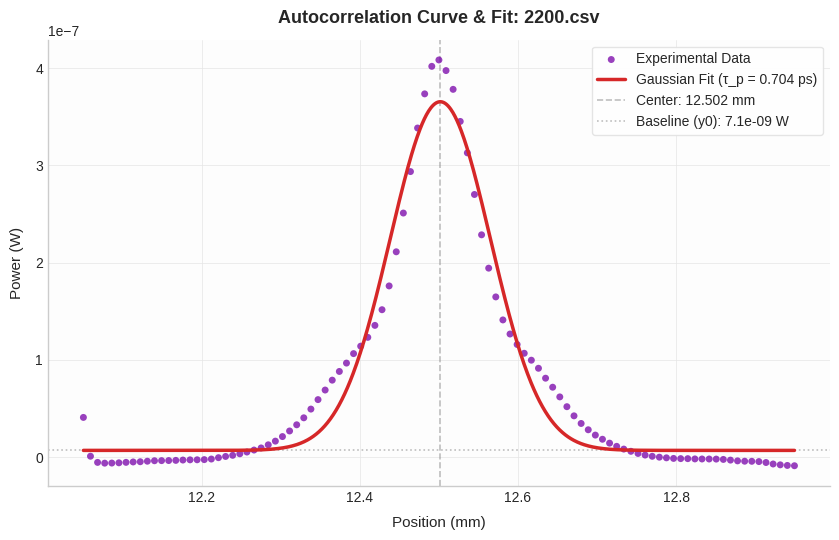

--------------------------------------------------

=== File: 3000.csv ===
Autocorrelation FWHM (mm): 0.21913 mm
Pulse Duration (tau_p): 1.034 ps


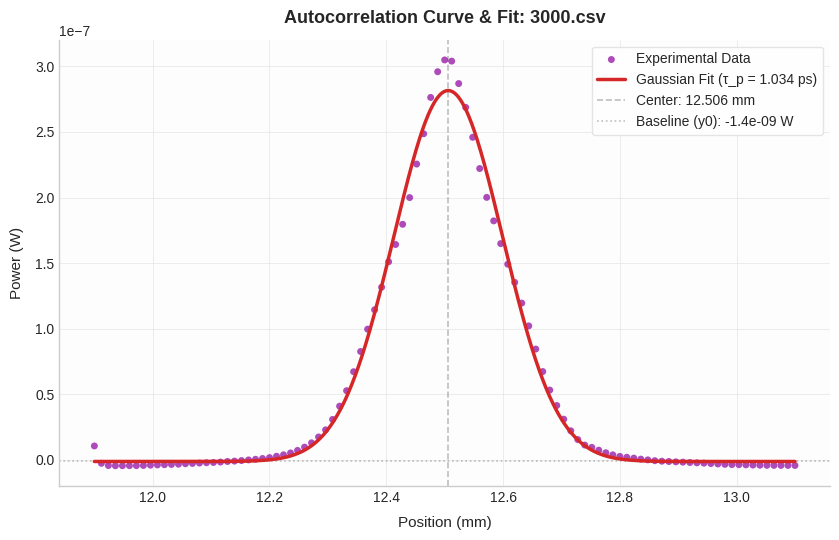

--------------------------------------------------

=== File: 3500.csv ===
Autocorrelation FWHM (mm): 0.27000 mm
Pulse Duration (tau_p): 1.274 ps


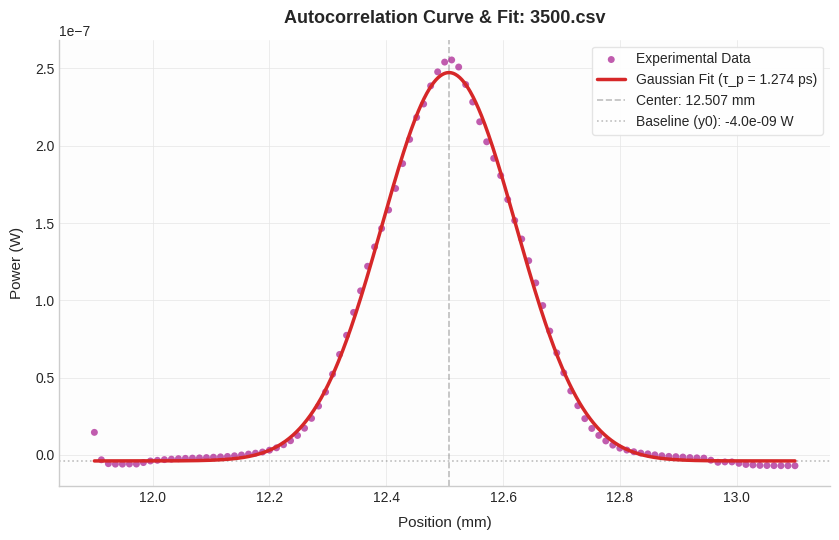

--------------------------------------------------

=== File: 5000.csv ===
Autocorrelation FWHM (mm): 0.39081 mm
Pulse Duration (tau_p): 1.844 ps


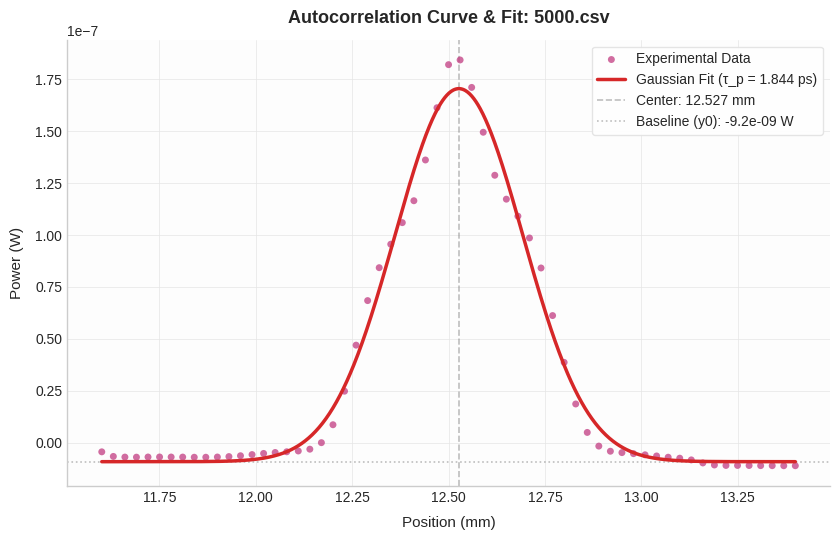

--------------------------------------------------

=== File: 7200.csv ===
Autocorrelation FWHM (mm): 0.61759 mm
Pulse Duration (tau_p): 2.913 ps


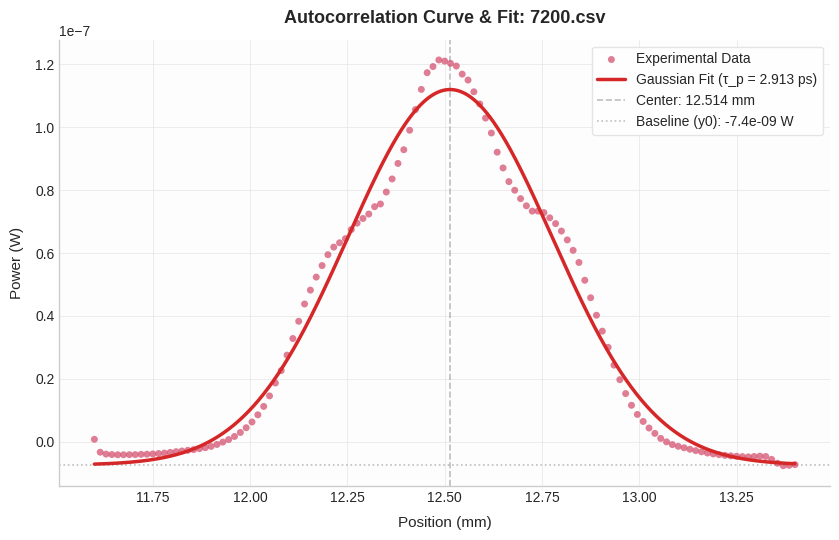

--------------------------------------------------

=== File: 8200.csv ===
Autocorrelation FWHM (mm): 0.70532 mm
Pulse Duration (tau_p): 3.327 ps


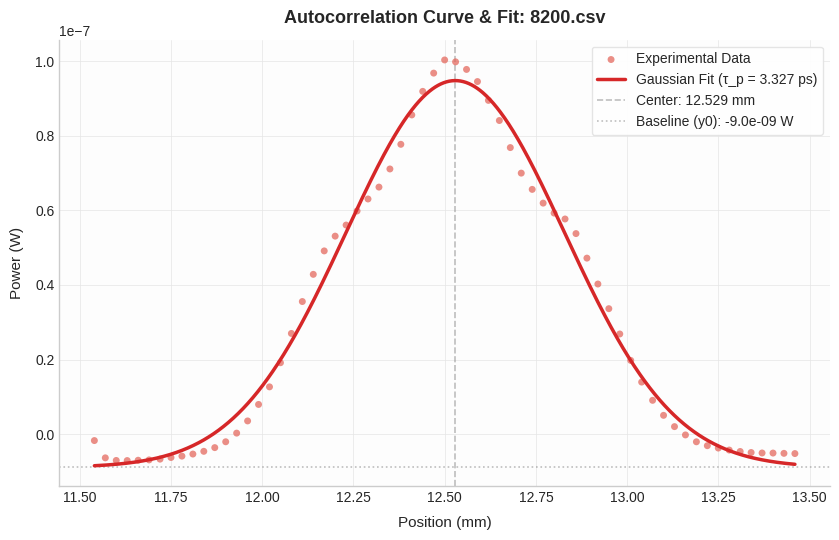

--------------------------------------------------

=== File: 9000.csv ===
Autocorrelation FWHM (mm): 0.75952 mm
Pulse Duration (tau_p): 3.583 ps


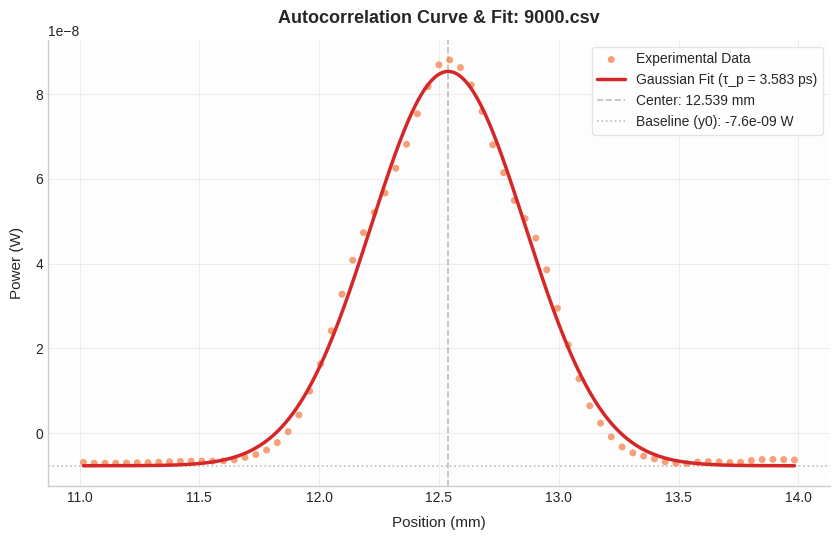

--------------------------------------------------

=== File: 9500.csv ===
Autocorrelation FWHM (mm): 0.80711 mm
Pulse Duration (tau_p): 3.807 ps


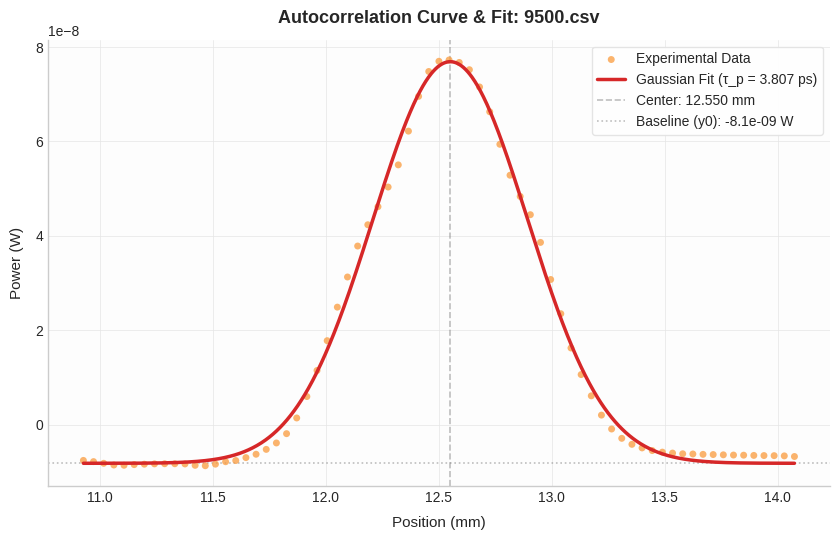

--------------------------------------------------

=== File: 10000.csv ===
Autocorrelation FWHM (mm): 0.84701 mm
Pulse Duration (tau_p): 3.996 ps


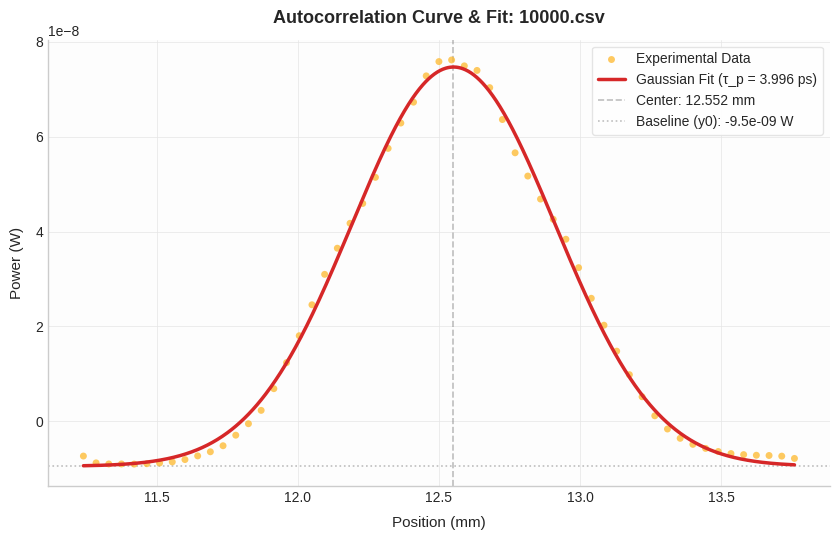

--------------------------------------------------

=== File: 13000.csv ===
Autocorrelation FWHM (mm): 1.16510 mm
Pulse Duration (tau_p): 5.496 ps


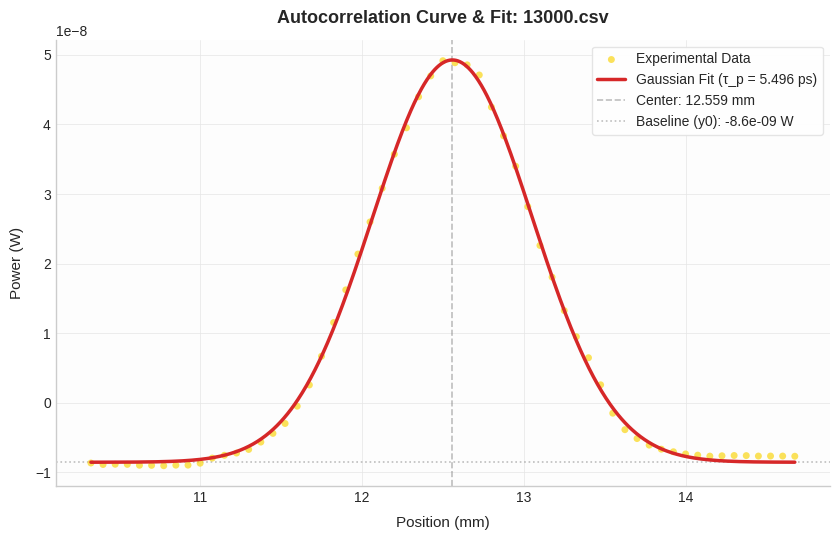

--------------------------------------------------

=== File: 20000.csv ===
Autocorrelation FWHM (mm): 1.85963 mm
Pulse Duration (tau_p): 8.773 ps


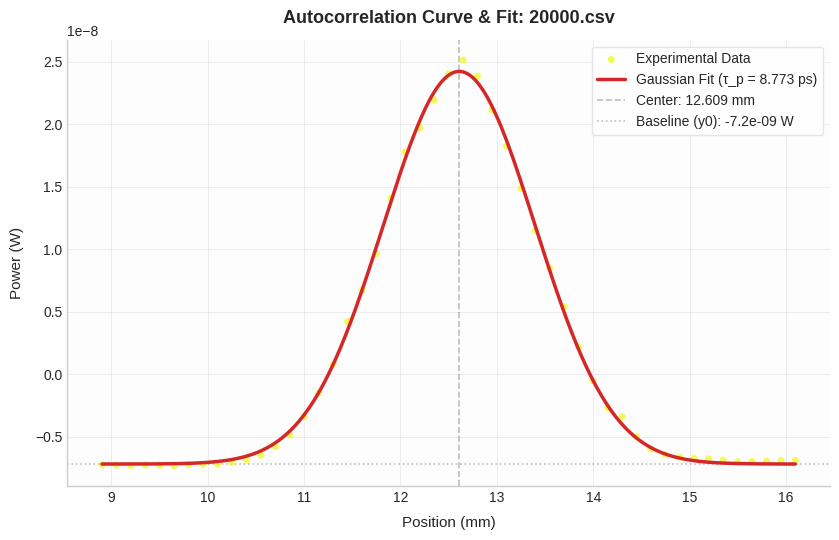

--------------------------------------------------



In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

filenames = [
    '1500.csv', '1800.csv', '2100.csv', '2200.csv',
    '3000.csv', '3500.csv', '5000.csv', '7200.csv',
    '8200.csv', '9000.csv', '9500.csv', '10000.csv',
    '13000.csv', '20000.csv'
]

# Gaussian Function
def gaussian_func(x, y0, amplitude, center, fwhm):
    sigma = fwhm / (2.0 * np.sqrt(2.0 * np.log(2.0)))
    return y0 + amplitude * np.exp(-((x - center) ** 2) / (2.0 * (sigma ** 2)))

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
colors = plt.get_cmap('plasma', len(filenames))

for idx, filename in enumerate(filenames):
    try:
        skip_lines = 0
        with open(filename, 'r') as f:
            for line in f:
                skip_lines += 1
                if '[Data]' in line:
                    break


        df = pd.read_csv(filename, skiprows=skip_lines)

        x = df['Position(mm)'].values
        y = df['Power(W)'].values


        y0_guess = np.min(y)
        amp_guess = np.max(y) - y0_guess
        center_guess = x[np.argmax(y)]
        fwhm_guess = (x.max() - x.min()) / 5.0

        u0 = [y0_guess, amp_guess, center_guess, fwhm_guess]


        popt, pcov = curve_fit(gaussian_func, x, y, p0=u0)
        y0_fit, amp_fit, center_fit, fwhm_mm_fit = popt


        c = 299792458.0  # Speed of light (m/s)
        fwhm_ps = (fwhm_mm_fit * 1e-3 * 2.0 / c) * 1e12  # Autocorrelation FWHM in ps
        tau_p_ps = fwhm_ps / 1.4142  # Deconvolution for Gaussian pulse


        print(f"=== File: {filename} ===")
        print(f"Autocorrelation FWHM (mm): {fwhm_mm_fit:.5f} mm")
        print(f"Pulse Duration (tau_p): {tau_p_ps:.3f} ps")


        fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=100)
        ax.set_facecolor('#fdfdfd')

        color = colors(idx)

        ax.scatter(x, y, color=color, s=25, alpha=0.75, edgecolors='none', label='Experimental Data', zorder=3)


        x_fit = np.linspace(x.min(), x.max(), 1000)
        y_fit = gaussian_func(x_fit, *popt)
        ax.plot(x_fit, y_fit, color='#d62728', linewidth=2.5, label=f'Gaussian Fit (\u03c4_p = {tau_p_ps:.3f} ps)', zorder=4)

        ax.axvline(center_fit, color='gray', linestyle='--', alpha=0.5, linewidth=1.2, label=f'Center: {center_fit:.3f} mm', zorder=1)
        ax.axhline(y0_fit, color='gray', linestyle=':', alpha=0.5, linewidth=1.2, label=f'Baseline (y0): {y0_fit:.1e} W', zorder=1)

        ax.set_xlabel('Position (mm)', fontsize=11, fontweight='medium', labelpad=8)
        ax.set_ylabel('Power (W)', fontsize=11, fontweight='medium', labelpad=8)
        ax.set_title(f'Autocorrelation Curve & Fit: {filename}', fontsize=13, fontweight='semibold', pad=12)


        ax.grid(True, which='both', linestyle='-', linewidth=0.5, color='#e5e5e5')
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)

        ax.legend(frameon=True, facecolor='white', framealpha=0.9, edgecolor='#e2e2e2', loc='upper right', fontsize=10)
        plt.tight_layout()
        plt.show()
        print("-" * 50 + "\n")

    except FileNotFoundError:
        print(f"Error: File {filename} not found. Skip it or upload it to the directory.\n")
    except Exception as e:
        print(f"Could not process file {filename}: {e}\n")